In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

In [34]:
df = pd.read_csv("data/games.csv")

df.head()

,BGGId,Name,Description,YearPublished,GameWeight,AvgRating,BayesAvgRating,StdDev,MinPlayers,MaxPlayers,...,Rank:partygames,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
0,1,Die Macher,die macher game seven sequential political rac...,1986,4.3206,7.61428,7.10363,1.57979,3,5,...,21926,21926,0,1,0,0,0,0,0,0
1,2,Dragonmaster,dragonmaster tricktaking card game base old ga...,1981,1.9630,6.64537,5.78447,1.45440,3,4,...,21926,21926,0,1,0,0,0,0,0,0
2,3,Samurai,samurai set medieval japan player compete gain...,1998,2.4859,7.45601,7.23994,1.18227,2,4,...,21926,21926,0,1,0,0,0,0,0,0
3,4,Tal der Könige,triangular box luxurious large block tal der k...,1992,2.6667,6.60006,5.67954,1.23129,2,4,...,21926,21926,0,0,0,0,0,0,0,0
4,5,Acquire,acquire player strategically invest business t...,1964,2.5031,7.33861,7.14189,1.33583,2,6,...,21926,21926,0,1,0,0,0,0,0,0


In [35]:
df2 = pd.concat([df.iloc[:,:2],df.iloc[:,38:]], axis=1)
df2.head(20)

,BGGId,Name,Rank:partygames,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
0,1,Die Macher,21926,21926,0,1,0,0,0,0,0,0
1,2,Dragonmaster,21926,21926,0,1,0,0,0,0,0,0
2,3,Samurai,21926,21926,0,1,0,0,0,0,0,0
3,4,Tal der Könige,21926,21926,0,0,0,0,0,0,0,0
4,5,Acquire,21926,21926,0,1,0,0,0,0,0,0
5,6,Mare Mediterraneum,21926,21926,0,0,0,0,0,0,0,0
6,7,Cathedral,21926,21926,0,0,0,0,0,1,0,0
7,8,Lords of Creation,21926,21926,0,0,0,0,0,0,0,0
8,9,El Caballero,21926,21926,0,1,0,0,0,0,0,0
9,10,Elfenland,21926,21926,0,0,0,1,0,0,0,0


In [36]:
print("total rows: ", df2.shape[0])
print(df2.iloc[:, -8:].sum())
print(sum(df2.iloc[:, -8:].sum()))

total rows:  21925
Cat:Thematic     1224
Cat:Strategy     2319
Cat:War          3530
Cat:Family       2316
Cat:CGS           303
Cat:Abstract     1115
Cat:Party         640
Cat:Childrens     881
dtype: int64
12328


## Categories and average rating
The selected columns contain eight category indicators (0 = absent, 1 = present) and two category ranks. Games can belong to multiple categories, so category counts can exceed the number of games. We use `AvgRating` to explore associations with category membership. Ranks are excluded from correlations because they are based on ratings and can contain placeholder ranks for unranked games.


,Missing values
BGGId,0
Name,0
Rank:partygames,0
Rank:childrensgames,0
Cat:Thematic,0
Cat:Strategy,0
Cat:War,0
Cat:Family,0
Cat:CGS,0
Cat:Abstract,0


,AvgRating
count,21925.000000
mean,6.424922
std,0.932477
min,1.041330
25%,5.836960
50%,6.453950
75%,7.052450
max,9.914290


Games with no category: 11184
Games in multiple categories: 1574


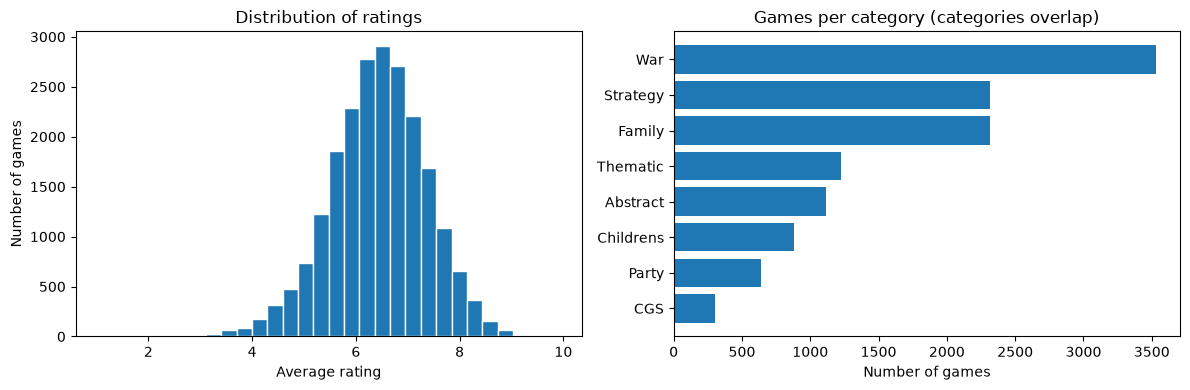

In [ ]:
# Add rating after the existing category-count cell to preserve its last-eight-column selection.
df2 = df2.copy()
df2["AvgRating"] = pd.to_numeric(df.loc[df2.index, "AvgRating"], errors="coerce")
category_cols = [col for col in df2.columns if col.startswith("Cat:")]

# Basic checks: missing values, rating distribution and category membership.
display(df2.isna().sum().rename("Missing values").to_frame())
display(df2["AvgRating"].describe().to_frame())
category_counts = df2[category_cols].sum().sort_values()
print("Games with no category:", (df2[category_cols].sum(axis=1) == 0).sum())
print("Games in multiple categories:", (df2[category_cols].sum(axis=1) > 1).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df2["AvgRating"].dropna(), bins=30, edgecolor="white")
axes[0].set(xlabel="Average rating", ylabel="Number of games", title="Distribution of ratings")
axes[1].barh(category_counts.index.str.replace("Cat:", "", regex=False), category_counts)
axes[1].set(xlabel="Number of games", title="Games per category (categories overlap)")
plt.tight_layout()
plt.show()


,Games with rating,Mean rating (present),Mean rating (absent),Median rating (present),Mean difference,Mean minus all games,Correlation with rating
Category,,,,,,,
Childrens,881,5.528,6.462,5.567,-0.935,-0.897,-0.197
Abstract,1115,6.237,6.435,6.261,-0.198,-0.188,-0.047
Party,640,6.291,6.429,6.342,-0.138,-0.134,-0.025
CGS,303,6.398,6.425,6.452,-0.027,-0.027,-0.003
Family,2316,6.424,6.425,6.452,-0.001,-0.001,-0.000
Thematic,1224,6.805,6.402,6.812,0.402,0.380,0.099
War,3530,6.880,6.338,6.891,0.543,0.455,0.214
Strategy,2319,6.954,6.362,6.958,0.592,0.529,0.195


/tmp/ipykernel_49174/2378984979.py:26: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = axes[0].boxplot(groups, vert=False, showfliers=False, patch_artist=True)


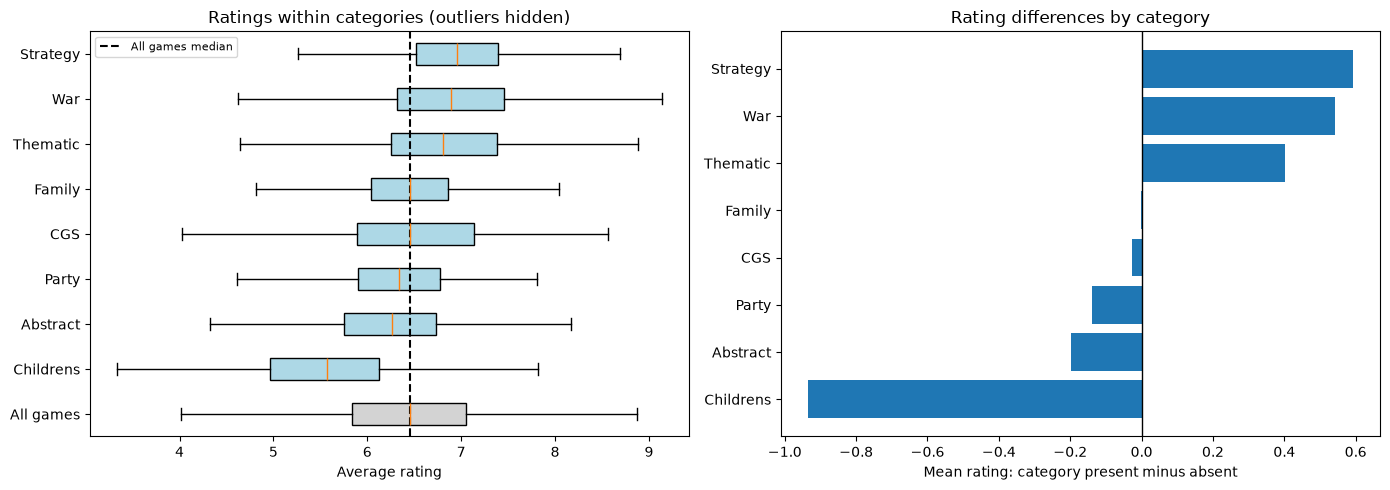

In [38]:
# Compare games with each category against games without it.
# Whole-sample baseline: each game contributes once, including uncategorized games.
baseline = df2["AvgRating"].dropna()
rows = []
for col in category_cols:
    present = df2.loc[df2[col] == 1, "AvgRating"].dropna()
    absent = df2.loc[df2[col] == 0, "AvgRating"].dropna()
    rows.append({
        "Category": col.replace("Cat:", ""),
        "Games with rating": len(present),
        "Mean rating (present)": present.mean(),
        "Mean rating (absent)": absent.mean(),
        "Median rating (present)": present.median(),
        "Mean difference": present.mean() - absent.mean(),
        "Mean minus all games": present.mean() - baseline.mean(),
        "Correlation with rating": df2[col].corr(df2["AvgRating"]),
    })

category_summary = pd.DataFrame(rows).set_index("Category").sort_values("Mean difference")
display(category_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ordered_cols = ["Cat:" + name for name in category_summary.index]
groups = [df2.loc[df2[col] == 1, "AvgRating"].dropna() for col in ordered_cols]
groups = [baseline] + groups
boxes = axes[0].boxplot(groups, vert=False, showfliers=False, patch_artist=True)
for i, box in enumerate(boxes["boxes"]):
    box.set_facecolor("lightgray" if i == 0 else "lightblue")
axes[0].set_yticks(range(1, len(groups) + 1), ["All games"] + list(category_summary.index))
axes[0].axvline(baseline.median(), color="black", linestyle="--", label="All games median")
axes[0].legend(fontsize=8)
axes[0].set(xlabel="Average rating", title="Ratings within categories (outliers hidden)")
axes[1].barh(category_summary.index, category_summary["Mean difference"])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(xlabel="Mean rating: category present minus absent", title="Rating differences by category")
plt.tight_layout()
plt.show()


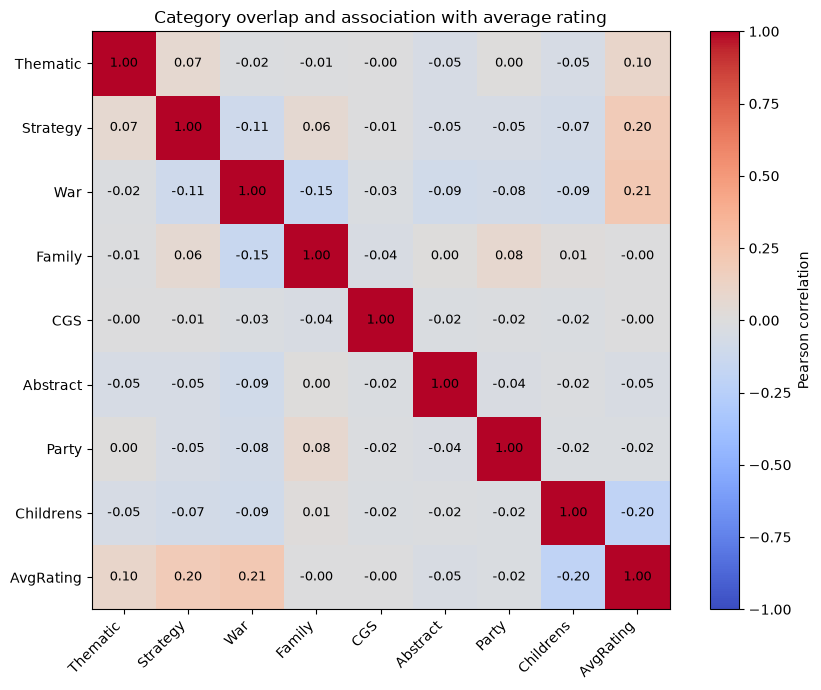

In [39]:
# Pearson correlation for binary category indicators is point-biserial correlation.
# Positive values mean games in the category tend to have higher ratings.
corr = df2[category_cols + ["AvgRating"]].corr()
labels = corr.columns.str.replace("Cat:", "", regex=False)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Category overlap and association with average rating")
plt.tight_layout()
plt.show()


### Interpreting the results
- The mean difference compares games belonging to a category with games outside it. A positive difference means a higher average rating for that category.
- Correlations range from -1 to 1; values near zero indicate little linear association. Category-to-category correlations help identify overlapping categories.
- These are exploratory associations, not causal effects or significance tests. Categories overlap, group sizes differ, and factors such as game complexity, publication year and the number of ratings may also explain differences.


## Does belonging to more categories relate to rating?
Zero means no category is recorded in these eight indicators. The group with three categories has only 13 games, so its average is uncertain. The association is descriptive and does not establish causation.

,count,mean,median,std,q1,q3
Category count,,,,,,
0,11184,6.250,6.256,0.959,5.644,6.867
1,9167,6.612,6.654,0.880,6.070,7.224
2,1561,6.581,6.596,0.793,6.108,7.062
3,13,6.467,6.301,0.714,6.129,7.001


Pearson correlation: 0.172


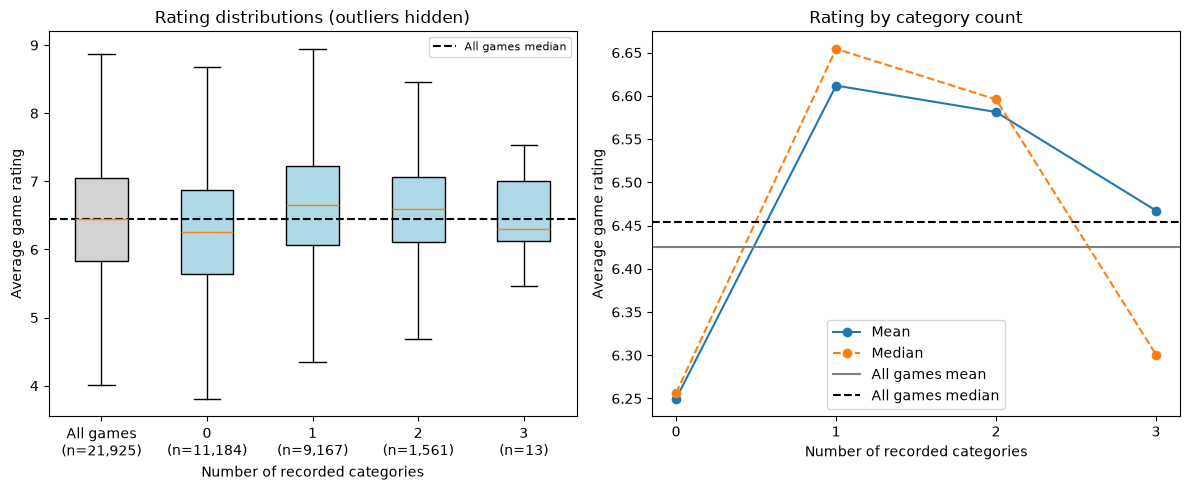

In [40]:
# Number of recorded categories per game and its association with rating.
category_cols = [c for c in df2.columns if c.startswith("Cat:")]
category_count_data = df2[["AvgRating"]].copy()
category_count_data["Category count"] = df2[category_cols].sum(axis=1)
count_summary = category_count_data.groupby("Category count")["AvgRating"].agg(
    count="count", mean="mean", median="median", std="std",
    q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)
)
display(count_summary.round(3))
print("Pearson correlation:", category_count_data.corr().loc["Category count", "AvgRating"].round(3))

baseline = df2["AvgRating"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
counts = count_summary.index
values = [category_count_data.loc[category_count_data["Category count"] == k, "AvgRating"].dropna() for k in counts]
boxes = axes[0].boxplot([baseline] + values, showfliers=False, patch_artist=True)
for i, box in enumerate(boxes["boxes"]):
    box.set_facecolor("lightgray" if i == 0 else "lightblue")
axes[0].set_xticks(range(1, len(counts) + 2), [f"All games\n(n={len(baseline):,})"] + [f"{int(k)}\n(n={len(v):,})" for k, v in zip(counts, values)])
axes[0].axhline(baseline.median(), color="black", linestyle="--", label="All games median")
axes[0].legend(fontsize=8)
axes[0].set(xlabel="Number of recorded categories", ylabel="Average game rating", title="Rating distributions (outliers hidden)")
axes[1].plot(counts, count_summary["mean"], "o-", label="Mean")
axes[1].plot(counts, count_summary["median"], "o--", label="Median")
axes[1].axhline(baseline.mean(), color="gray", linestyle="-", label="All games mean")
axes[1].axhline(baseline.median(), color="black", linestyle="--", label="All games median")
axes[1].set_xticks(counts)
axes[1].set(xlabel="Number of recorded categories", ylabel="Average game rating", title="Rating by category count")
axes[1].legend()
plt.tight_layout()
plt.show()


## Which category pairs overlap most?
Jaccard overlap divides the number of games in both categories by the number in either category. Each game is counted once in the union. The directional percentages instead describe how much of category A belongs to B and vice versa. Games with no recorded category do not contribute to these pairwise unions.


,Category A,Category B,Games in both,Games in either,Jaccard overlap (%),A also in B (%),B also in A (%)
0,Strategy,Family,371,4264,8.70,16.00,16.02
1,Thematic,Strategy,236,3307,7.14,19.28,10.18
2,Family,Party,156,2800,5.57,6.74,24.38
3,Family,Childrens,112,3085,3.63,4.84,12.71
4,Family,Abstract,120,3311,3.62,5.18,10.76
5,Thematic,War,157,4597,3.42,12.83,4.45
6,Thematic,Family,116,3424,3.39,9.48,5.01
7,Thematic,Party,38,1826,2.08,3.10,5.94
8,Strategy,War,109,5740,1.90,4.70,3.09
9,Strategy,Abstract,46,3388,1.36,1.98,4.13


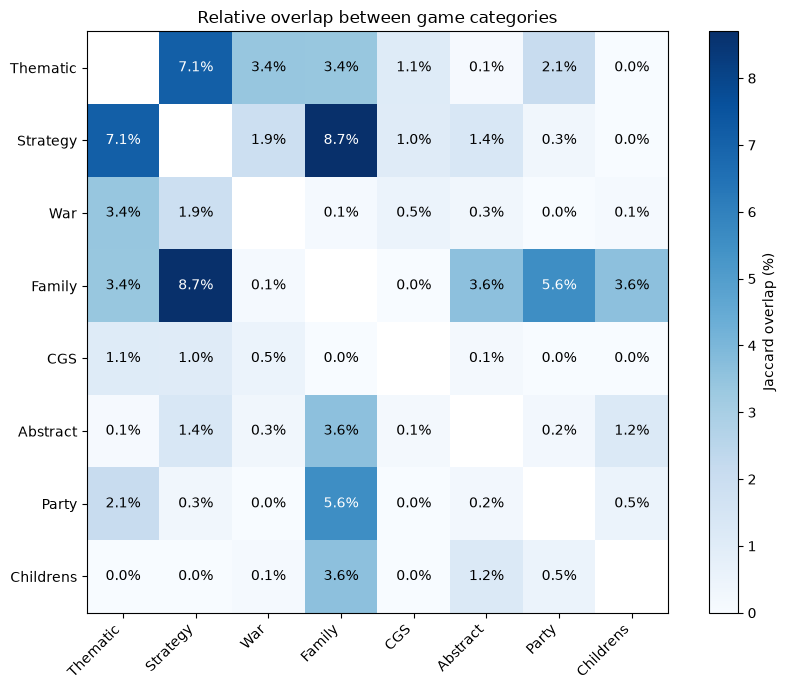

In [ ]:
# Jaccard overlap = games in both categories / games in either category.
category_cols = [c for c in df2.columns if c.startswith("Cat:")]
membership = df2[category_cols].eq(1)
labels = [c.replace("Cat:", "") for c in category_cols]
overlap_matrix = pd.DataFrame(index=labels, columns=labels, dtype=float)

rows = []
for a in category_cols:
    for b in category_cols:
        both = (membership[a] & membership[b]).sum()
        either = (membership[a] | membership[b]).sum()
        overlap_matrix.loc[
            a.replace("Cat:", ""), b.replace("Cat:", "")
        ] = both / either if either else np.nan

for a, b in combinations(category_cols, 2):
    both = (membership[a] & membership[b]).sum()
    either = (membership[a] | membership[b]).sum()
    count_a, count_b = membership[a].sum(), membership[b].sum()

    rows.append({
        "Category A": a.replace("Cat:", ""),
        "Category B": b.replace("Cat:", ""),
        "Games in both": both,
        "Games in either": either,
        "Jaccard overlap (%)": 100 * both / either if either else np.nan,
        "A also in B (%)": 100 * both / count_a if count_a else np.nan,
        "B also in A (%)": 100 * both / count_b if count_b else np.nan,
    })

overlap_summary = (
    pd.DataFrame(rows)
    .sort_values("Jaccard overlap (%)", ascending=False)
    .reset_index(drop=True)
)
display(overlap_summary.round(2))

# Hide self-overlap using DataFrame assignment to avoid the read-only array error.
plot_matrix = overlap_matrix.copy() * 100
for i in range(len(plot_matrix)):
    plot_matrix.iat[i, i] = np.nan

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(plot_matrix, cmap="Blues", vmin=0)

ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        if i != j:
            value = plot_matrix.iloc[i, j]
            ax.text(
                j, i, f"{value:.1f}%",
                ha="center", va="center",
                color="white" if value > plot_matrix.max().max() / 2 else "black",
            )

fig.colorbar(im, ax=ax, label="Jaccard overlap (%)")
ax.set_title("Relative overlap between game categories")
plt.tight_layout()
plt.show()

In the current dataset, **Strategy + Family** has the greatest Jaccard overlap: **371 shared games, or 8.70%** of games in either category. Next are Thematic + Strategy (7.14%) and Family + Party (5.57%). Strategy + War has 109 shared games (1.90%). About 16% of Strategy games are also Family games; 24.4% of Party games are also Family games. Directional percentages and Jaccard overlap answer different questions.
